# Graph Neural Network


<b> Objective: </b>
Create all the tables and figures to use in the report based on cached results and predictions.

----------------------

<i><b>Author: </b> Salvador Palma <br>
<b>Institution: </b> Copenhagen University </i>

## Section 2. Datasets

#### Table 1 
The three datasets, before and after preprocessing.

In [4]:
import json
import pandas as pd

def Schema(name):
    with open(f"Data/{name}.json") as f:
        schema = json.load(f)
    return schema["metaCols"] + schema["physicalCols"]

SOURCES = {
    "Whole Rock": ("Data/whole-rock.csv", "Data/Whole Rock/Mean Merge/Data.csv", Schema("whole-rock")),
    "Stream Sediment": ("Data/stream-sediment.csv", "Data/Stream Sediment/Mean Merge/Data.csv", Schema("stream-sediment")),
    "East Greenland": ("Data/Pierpaolo/greenland_portal.xlsx", "Data/Pierpaolo/Data.csv", Schema("pierpaolo")),
}

def Stats(rawPath, mergedPath, nonElements):
    
    
    raw = pd.read_excel(f"{rawPath}") if rawPath.endswith("xlsx") else pd.read_csv(f"{rawPath}", sep=";", low_memory=False)
    df = pd.read_csv(f"{mergedPath}", sep=";", low_memory=False)
    
    elements = [c for c in df.columns if c not in nonElements and "/" not in c]
    perLocation = df.groupby(["Longitude", "Latitude"]).size()
    colocated = perLocation[perLocation > 1].sum()
    
    return {
        "Raw rows": len(raw),
        "Raw element columns": len([c for c in raw.columns if c not in nonElements]),
        "Merged rows": len(df),
        "Merged element columns": len(elements),
        "Targets (coverage >= 1000)": int((df[elements].notna().sum() >= 1000).sum()),
        "Unique coordinate pairs": len(perLocation),
        "Co-located samples": f"{colocated} ({colocated / len(df):.1%})",
        "Max samples at one location": perLocation.max(),
        "Longitude span": round(df["Longitude"].max() - df["Longitude"].min(), 1),
        "Latitude span": round(df["Latitude"].max() - df["Latitude"].min(), 1),
    }

pd.DataFrame({name: Stats(*source) for name, source in SOURCES.items()})

c:\Users\salva\AppData\Local\Programs\Python\Python312\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Whole Rock,Stream Sediment,East Greenland
Raw rows,26068,20158,4154
Raw element columns,76,523,59
Merged rows,6957,17463,4000
Merged element columns,76,93,59
Targets (coverage >= 1000),48,71,13
Unique coordinate pairs,4498,16542,1668
Co-located samples,3458 (49.7%),1759 (10.1%),2809 (70.2%)
Max samples at one location,67,11,64
Longitude span,11.7,59.5,3.0
Latitude span,10.3,23.8,1.8


#### Figure 1
Sampling locations post-pre-processing on all datasets

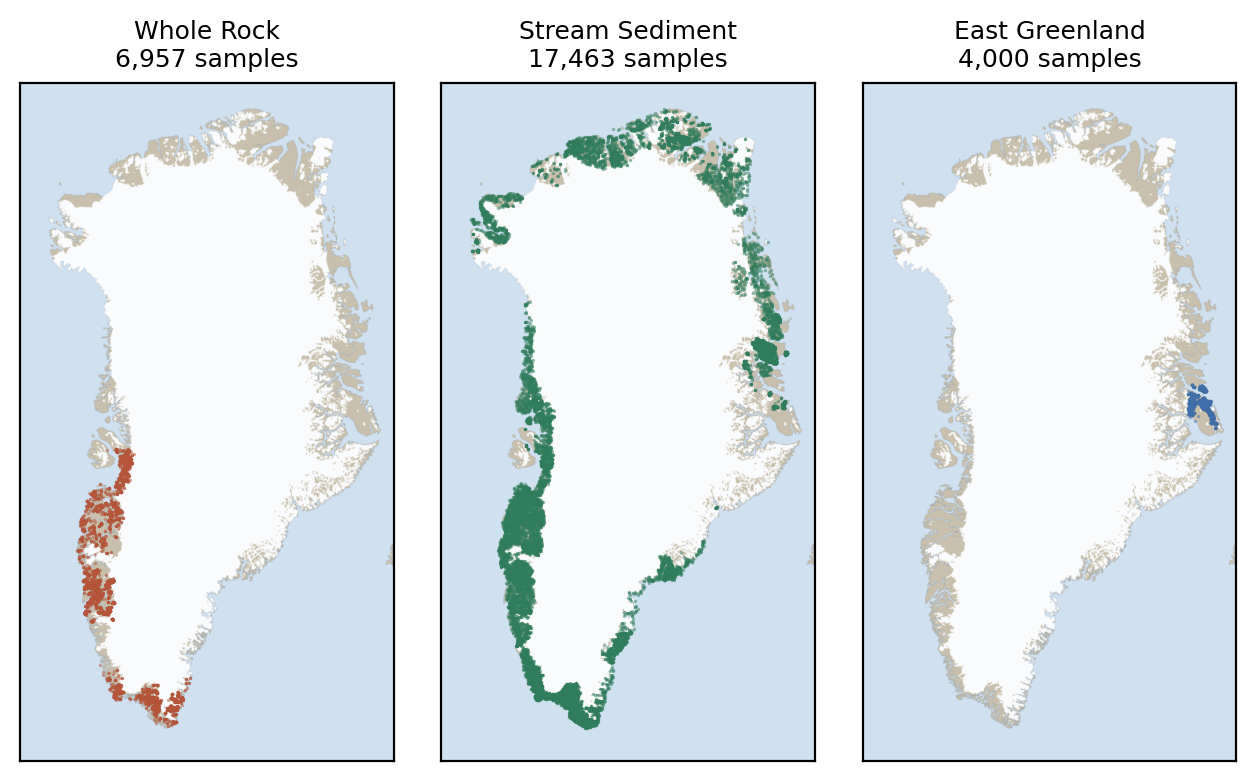

In [6]:
import matplotlib.pyplot as plt
from GreenlandUtils import BASEMAP_BBOX, BASEMAP_PATH, lonlatToUTM24N

COLOURS = {"Whole Rock": "#b4553a", "Stream Sediment": "#2f7d5c", "East Greenland": "#3f6ea8"}

fig, axes = plt.subplots(1, len(SOURCES), figsize=(8.1, 4.4), dpi=200)
fig.subplots_adjust(wspace=0.02)
basemap = plt.imread(BASEMAP_PATH)
minx, miny, maxx, maxy = BASEMAP_BBOX

for ax, (name, (_, mergedPath, _)) in zip(axes, SOURCES.items()):
    df = pd.read_csv(mergedPath, sep=";", usecols=["Longitude", "Latitude"]).dropna()
    x, y = lonlatToUTM24N(df["Longitude"].to_numpy(), df["Latitude"].to_numpy())

    ax.imshow(basemap, extent=(minx, maxx, miny, maxy), origin="upper", interpolation="bilinear", zorder=0)
    ax.scatter(x, y, s=1.4, c=COLOURS[name], alpha=0.5, linewidths=0, zorder=2)
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ax.set_aspect("equal")
    ax.set_title(f"{name}\n{len(df):,} samples", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.savefig("Report/figures/samples.png", dpi=200, bbox_inches="tight")
plt.show()

## Section 3. Results
### Subsection 3.1 Baseline
#### Table 3

In [7]:
import numpy as np

DATASETS = ["Whole Rock", "Stream Sediment"]
MODELS = {"RF": "RandomForest", "XGB": "XGBoost", "HGB": "HistGradientBoosting"}

def LoadResults(dataset, name):
    with open(f"Results/{dataset}/Mean Merge/{name}.json") as f:
        return {e: s for e, s in json.load(f).items() if s.get("r2") is not None}

def PooledR2(results):
    residual = sum(((np.array(s["y_test"]) - np.array(s["y_pred"])) ** 2).sum() for s in results.values())
    total = sum(((np.array(s["y_test"]) - np.mean(s["y_test"])) ** 2).sum() for s in results.values())
    return 1 - residual / total

def Metrics(results):
    r2 = [s["r2"] for s in results.values()]
    return {"Mean": np.mean(r2), "Median": np.median(r2), "Pooled": PooledR2(results)}

pd.DataFrame({(dataset, model): Metrics(LoadResults(dataset, f"{name}_KFold_Cov1000"))
              for dataset in DATASETS for model, name in MODELS.items()}).round(4)

Whole Rock                 Stream Sediment                
               RF     XGB     HGB              RF     XGB     HGB
Mean       0.7856  0.7954  0.7983          0.8587  0.8664  0.8676
Median     0.8076  0.8240  0.8284          0.8908  0.9022  0.9012
Pooled     0.7809  0.7927  0.7963          0.8241  0.8350  0.8352

### Subsection 3.2 KNN

#### Table 4

The four KNN encodings on k = 20 and their respective mean R2 and the respective
difference to the baseline

In [10]:
VARIANTS = {"Baseline": "HistGradientBoosting_KFold_Cov1000",
            **{v: f"K-Sweep_20_{v}_HistGradientBoosting_ExcludingColocation_Cov1000" for v in "ABCD"}}

table = {}
for dataset in DATASETS:
    r2 = {v: np.mean([s["r2"] for s in LoadResults(dataset, name).values()]) for v, name in VARIANTS.items()}
    table[(dataset, "Mean R2")] = r2
    table[(dataset, "Delta")] = {v: r2[v] - r2["Baseline"] for v in r2}

pd.DataFrame(table).round(4)

Whole Rock         Stream Sediment        
            Mean R2   Delta         Mean R2   Delta
Baseline     0.7983  0.0000          0.8676  0.0000
A            0.8045  0.0062          0.8757  0.0081
B            0.8046  0.0063          0.8724  0.0048
C            0.8125  0.0142          0.8801  0.0125
D            0.7980 -0.0003          0.8659 -0.0017

#### Figure 3
Mean $R^2$ as neighbourhood size $k$ varies. Bands are the fold standard deviation.

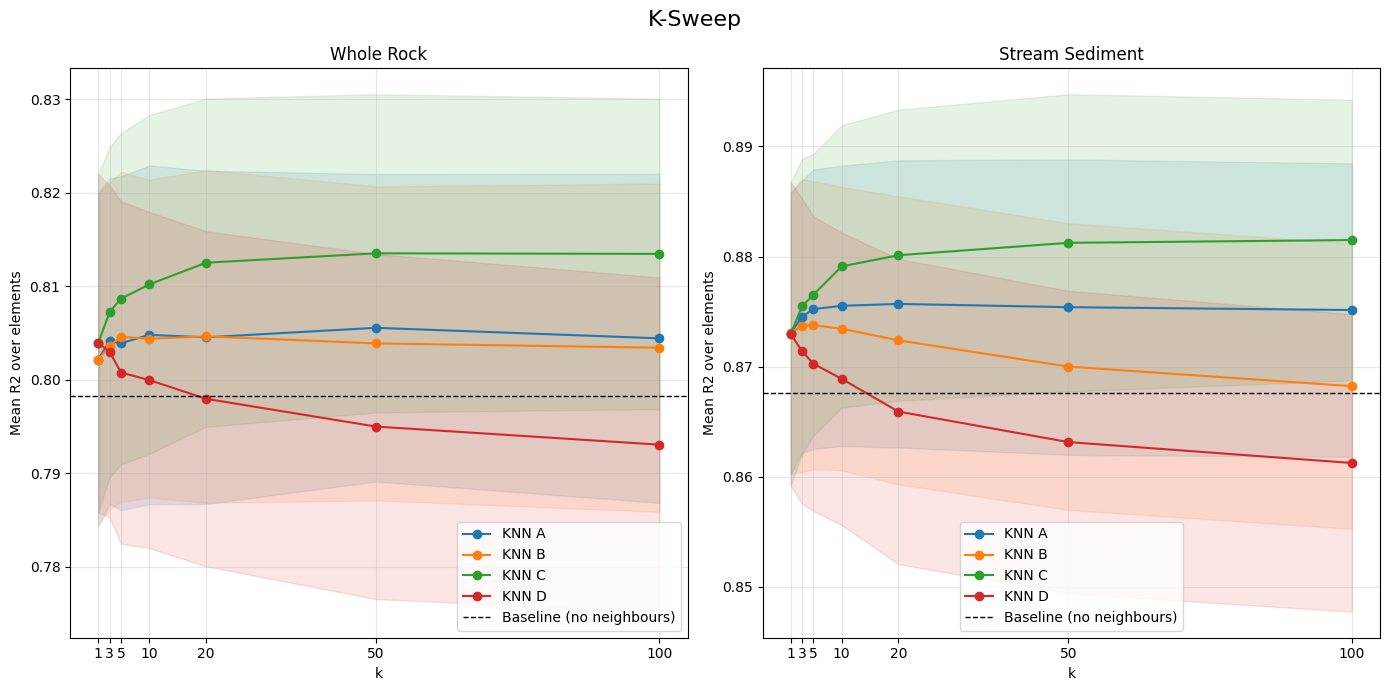

In [11]:
KS = [1, 3, 5, 10, 20, 50, 100]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, dataset in zip(axes, DATASETS):
    for v in "ABCD":
        sweep = [LoadResults(dataset, f"K-Sweep_{k}_{v}_HistGradientBoosting_ExcludingColocation_Cov1000") for k in KS]
        means = np.array([np.mean([s["r2"] for s in r.values()]) for r in sweep])
        stds = np.array([np.mean([s["r2_std"] for s in r.values()]) for r in sweep])

        line, = ax.plot(KS, means, marker="o", label=f"KNN {v}")
        ax.fill_between(KS, means - stds, means + stds, alpha=0.12, color=line.get_color())

    baseline = np.mean([s["r2"] for s in LoadResults(dataset, "HistGradientBoosting_KFold_Cov1000").values()])
    ax.axhline(baseline, color="black", linestyle="--", linewidth=1, label="Baseline (no neighbours)")

    ax.set_xlabel("k")
    ax.set_ylabel("Mean R2 over elements")
    ax.set_title(dataset)
    ax.set_xticks(KS)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("K-Sweep", fontsize=16)
plt.tight_layout()
fig.savefig("Report/figures/ksweep.png", dpi=200, bbox_inches="tight")
plt.show()

### Subsection 3.3 Feature Sets

#### Figure 4
Mean ^2$ by feature type over the respective target sets for both datasets.

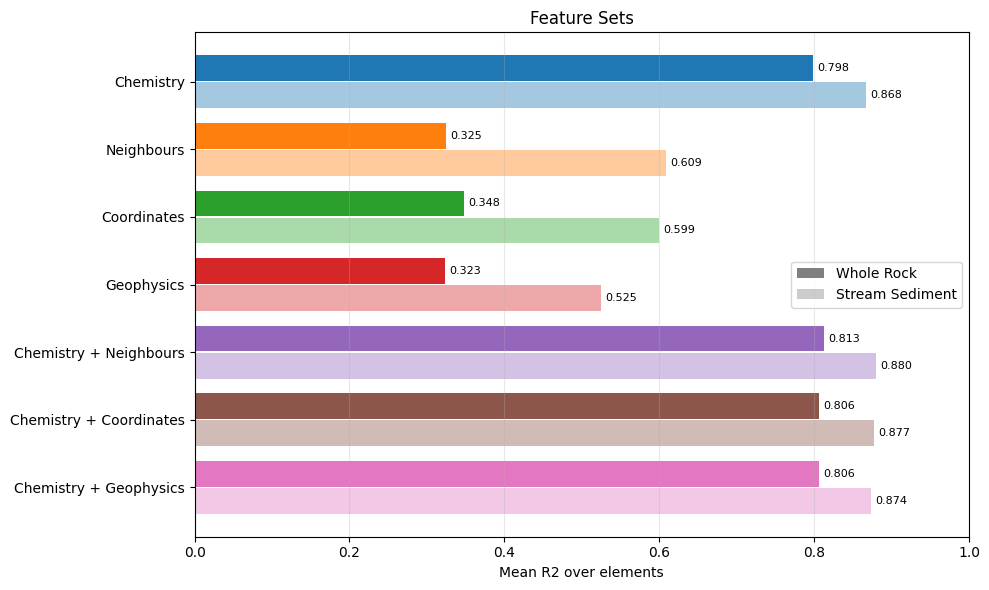

In [16]:
FEATURE_SETS = {
    "Chemistry": "HistGradientBoosting_KFold_FeatureSet_Chemistry_Cov1000",
    "Neighbours": "HistGradientBoosting_KFold_FeatureSet_Neighbours_Cov1000",
    "Coordinates": "HistGradientBoosting_KFold_FeatureSet_Location_Cov1000",
    "Geophysics": "HistGradientBoosting_KFold_FeatureSet_Physics_Cov1000",
    "Chemistry + Neighbours": "K-Sweep_20_C_HistGradientBoosting_ExcludingColocation_Cov1000",
    "Chemistry + Coordinates": "HistGradientBoosting_KFold_FeatureSet_Chemistry_Location_Cov1000",
    "Chemistry + Geophysics": "HistGradientBoosting_KFold_FeatureSet_Chemistry_Physics_Cov1000",
}

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(FEATURE_SETS))
colours = [f"C{i}" for i in range(len(FEATURE_SETS))]

for dataset, offset, alpha in [("Whole Rock", -0.2, 1.0), ("Stream Sediment", 0.2, 0.4)]:
    scores = [np.mean([s["r2"] for s in LoadResults(dataset, name).values()]) for name in FEATURE_SETS.values()]
    bars = ax.barh(y + offset, scores, 0.38, color=colours, alpha=alpha, label=dataset)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

legend = ax.legend()
for handle in legend.legend_handles:
    handle.set_facecolor("grey")

ax.set_yticks(y, list(FEATURE_SETS))
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Mean R2 over elements")
ax.set_title("Feature Sets")
ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
fig.savefig("Report/figures/featuresets.png", dpi=200, bbox_inches="tight")
plt.show()

### Subsection 3.4 Baseline Difficulty

#### Figure 5
Mean improvement over own chemistry, with targets binned by their baseline ^2$.

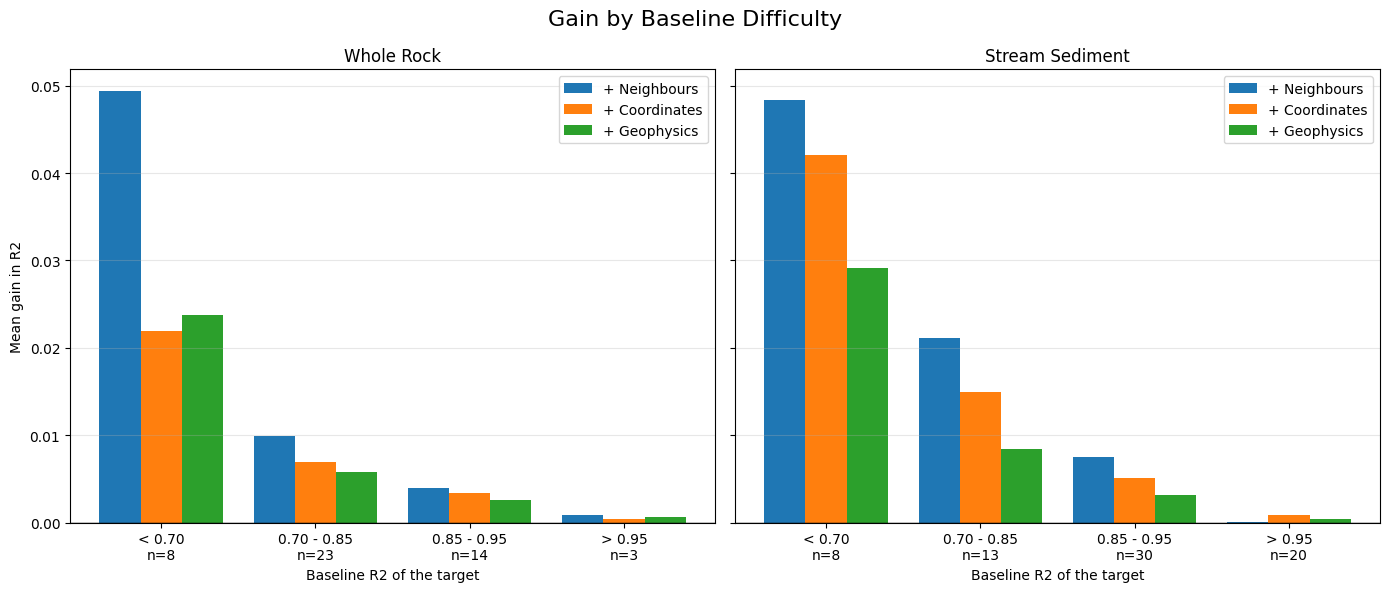

In [17]:
BINS = [(-np.inf, 0.70, "< 0.70"), (0.70, 0.85, "0.70 - 0.85"), (0.85, 0.95, "0.85 - 0.95"), (0.95, np.inf, "> 0.95")]
ADDED = {
    "+ Neighbours": "K-Sweep_20_C_HistGradientBoosting_ExcludingColocation_Cov1000",
    "+ Coordinates": "HistGradientBoosting_KFold_FeatureSet_Chemistry_Location_Cov1000",
    "+ Geophysics": "HistGradientBoosting_KFold_FeatureSet_Chemistry_Physics_Cov1000",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
x = np.arange(len(BINS))
width = 0.8 / len(ADDED)

for ax, dataset in zip(axes, DATASETS):
    baseline = LoadResults(dataset, "HistGradientBoosting_KFold_Cov1000")
    bins = [[e for e, s in baseline.items() if low <= s["r2"] < high] for low, high, _ in BINS]

    for i, (label, name) in enumerate(ADDED.items()):
        results = LoadResults(dataset, name)
        gains = [np.mean([results[e]["r2"] - baseline[e]["r2"] for e in elements]) for elements in bins]
        ax.bar(x + (i - 1) * width, gains, width, label=label)

    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x, [f"{label}\nn={len(elements)}" for (_, _, label), elements in zip(BINS, bins)])
    ax.set_xlabel("Baseline R2 of the target")
    ax.set_title(dataset)
    ax.grid(alpha=0.3, axis="y")
    ax.legend()

axes[0].set_ylabel("Mean gain in R2")
fig.suptitle("Gain by Baseline Difficulty", fontsize=16)
plt.tight_layout()
fig.savefig("Report/figures/difficulty.png", dpi=200, bbox_inches="tight")
plt.show()

### Subsection 3.5 Pathfinders

#### Table 5 and 6
The ten elements with the largest gain from neighbour (k = 20) and geophysical features on each dataset.

In [18]:
def TopGainers(name, n=10):
    columns = {}
    for dataset in DATASETS:
        baseline = LoadResults(dataset, "HistGradientBoosting_KFold_Cov1000")
        added = LoadResults(dataset, name)
        gains = pd.Series({e.split()[0]: added[e]["r2"] - s["r2"] for e, s in baseline.items()}).nlargest(n)
        columns[(dataset, "Element")] = gains.index
        columns[(dataset, "Delta R2")] = gains.values.round(3)
    return pd.DataFrame(columns, index=range(1, n + 1))

print("Table 5: neighbours (KNN C, k = 20)")
display(TopGainers(ADDED["+ Neighbours"]))
print("Table 6: geophysics")
display(TopGainers(ADDED["+ Geophysics"]))

Table 5: neighbours (KNN C, k = 20)


Whole Rock          Stream Sediment         
      Element Delta R2         Element Delta R2
1          Au    0.097               U    0.220
2          As    0.093              As    0.060
3          Sb    0.063              Br    0.043
4          Cs    0.049              Sb    0.041
5           S    0.035              Pb    0.034
6          Pb    0.028              Cs    0.031
7          Zn    0.020              Ca    0.031
8          Cu    0.020              Zn    0.030
9          Rb    0.019              Sr    0.028
10          U    0.018              Nb    0.024

Table 6: geophysics


Whole Rock          Stream Sediment         
      Element Delta R2         Element Delta R2
1          Au    0.046               U    0.187
2          As    0.037              Br    0.024
3          Cs    0.027              Ca    0.014
4           S    0.027              Zn    0.013
5          Sb    0.019              As    0.013
6           U    0.017               S    0.011
7          Cu    0.015              Sr    0.011
8       Fe2O3    0.013              Ba    0.011
9          Th    0.012              Sb    0.011
10         Ag    0.011              Nb    0.010

### Subsection 3.6 Chemical Isolation

#### Figure 6
Baseline ^2$ against companion strength. Area size is the gain from neighbours.

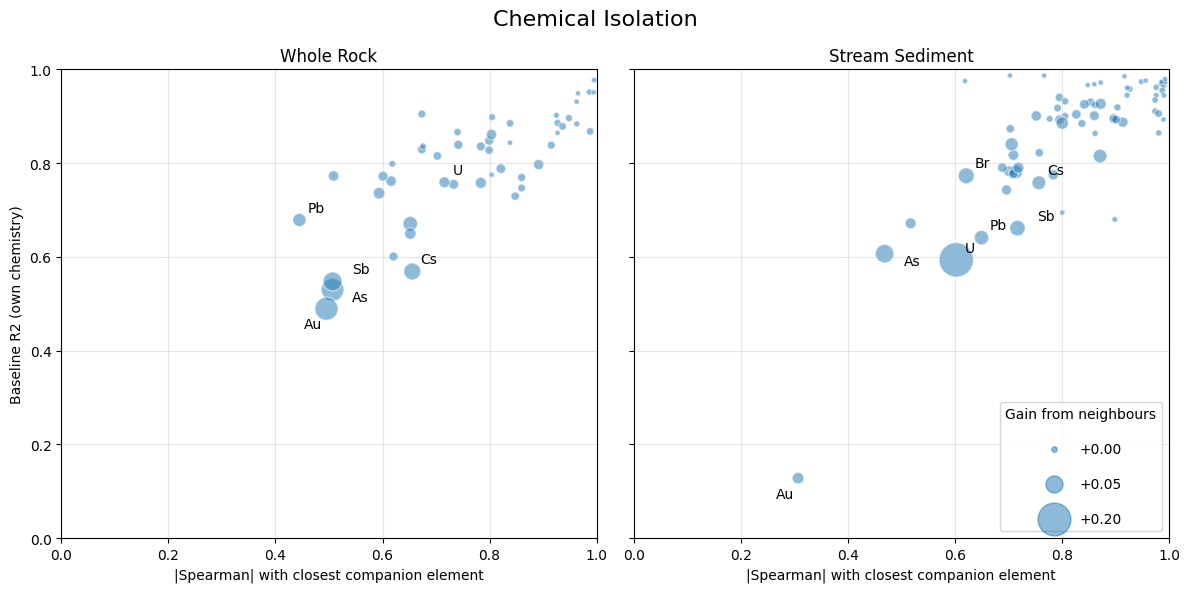

In [21]:
SCHEMAS = {"Whole Rock": "whole-rock", "Stream Sediment": "stream-sediment"}

def Companions(dataset):
    with open(f"Data/{SCHEMAS[dataset]}.json") as f:
        schema = json.load(f)
    df = pd.read_csv(f"Data/{dataset}/Mean Merge/Data.csv", sep=";", low_memory=False)
    elements = [c for c in df.columns if c not in schema["metaCols"] + schema["physicalCols"] and df[c].notna().sum() >= 10]

    rho = df[elements].corr(method="spearman", min_periods=100)
    rho = rho.mask(np.eye(len(elements), dtype=bool)).dropna(how="all").dropna(axis=1, how="all")
    elements = list(rho.index)
    best = rho.abs().idxmax()

    baseline = LoadResults(dataset, "HistGradientBoosting_KFold_Cov1000")
    neighbours = LoadResults(dataset, ADDED["+ Neighbours"])
    return pd.DataFrame({
        "Coverage": df[elements].notna().sum(),
        "Companion": best,
        "Spearman": [rho.loc[e, best[e]] for e in elements],
        "Partners > 0.8": (rho.abs() > 0.8).sum(),
        "Baseline": pd.Series({e: s["r2"] for e, s in baseline.items()}),
        "Gain": pd.Series({e: neighbours[e]["r2"] - s["r2"] for e, s in baseline.items()}),
    }, index=elements)

companions = {dataset: Companions(dataset) for dataset in DATASETS}
ANNOTATE = {"As": (14, -8), "Au": (-16, -14), "Sb": (14, 6), "Pb": (6, 6), "Cs": (6, 6), "U": (6, 6), "Br": (6, 6)}

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
largest = max(c["Gain"].max() for c in companions.values())

for ax, dataset in zip(axes, DATASETS):
    targets = companions[dataset].dropna(subset=["Baseline"])
    strength = targets["Spearman"].abs()
    ax.scatter(strength, targets["Baseline"], s=15 + 600 * targets["Gain"].clip(lower=0) / largest,
               alpha=0.5, edgecolors="white")
    for element, row in targets.iterrows():
        if element.split()[0] in ANNOTATE:
            ax.annotate(element.split()[0], (abs(row["Spearman"]), row["Baseline"]), xytext=ANNOTATE[element.split()[0]], textcoords="offset points")

    ax.set_xlabel("|Spearman| with closest companion element")
    ax.set_title(dataset)
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

for gain in [0.0, 0.05, 0.2]:
    axes[1].scatter([], [], s=15 + 600 * gain / largest, color="C0", alpha=0.5, label=f"+{gain:.2f}")
axes[1].legend(title="Gain from neighbours", loc="lower right", labelspacing=1.5)
axes[0].set_ylabel("Baseline R2 (own chemistry)")

fig.suptitle("Chemical Isolation", fontsize=16)
plt.tight_layout()
fig.savefig("Report/figures/isolation.png", dpi=200, bbox_inches="tight")
plt.show()

In [23]:
for dataset in DATASETS:
    targets = companions[dataset].dropna(subset=["Baseline"])
    isolated = targets["Partners > 0.8"] == 0
    print(dataset, f"r = {np.corrcoef(targets['Spearman'].abs(), targets['Baseline'])[0, 1]:.2f}",
          f"isolated {isolated.sum()}/{len(targets)}")
    display(targets.groupby(isolated.map({True: "Isolated", False: "Accompanied"}))[["Baseline", "Gain"]].mean().round(4))


Whole Rock r = 0.77 isolated 25/48


,Baseline,Gain
Partners > 0.8,,
Accompanied,0.8639,0.0042
Isolated,0.7380,0.0234


Stream Sediment r = 0.76 isolated 27/71


,Baseline,Gain
Partners > 0.8,,
Accompanied,0.9200,0.0047
Isolated,0.7822,0.0253


### Subsection 3.7 GNN

#### Figure 7
Mean ^2$ for the two graph architectures and KNN C across neighbourhood size, on the GNN's target set.

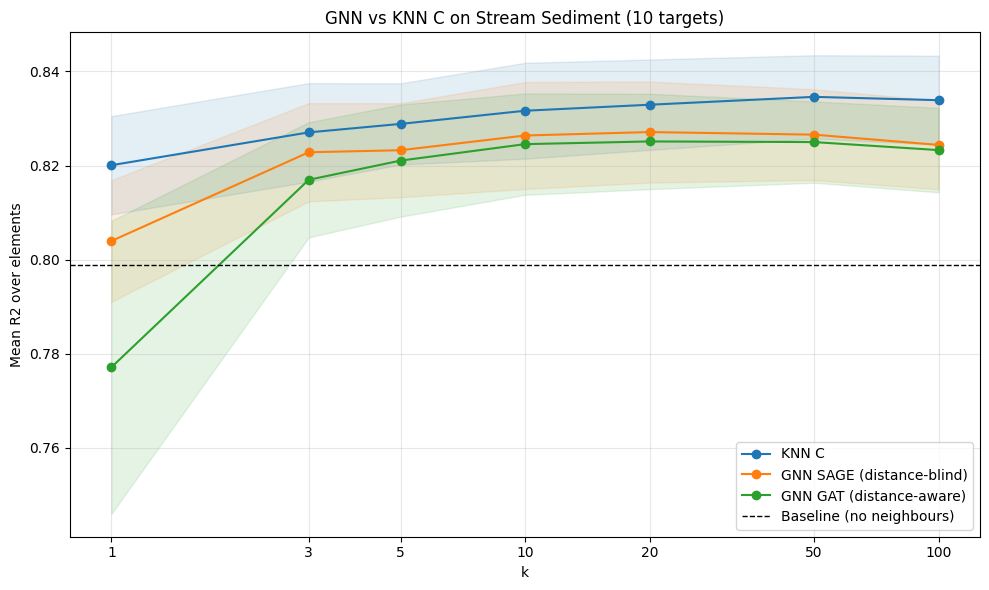

In [31]:
GNN_DATASET = "Stream Sediment"
GNN_FILE = "GNN_{model}_KFold_k{k}_TargetChannel"

def Curve(name, elements):
    runs = [LoadResults(GNN_DATASET, name.format(k=k)) for k in KS]
    means = np.array([np.mean([r[e]["r2"] for e in elements]) for r in runs])
    stds = np.array([np.mean([r[e]["r2_std"] for e in elements]) for r in runs])
    return means, stds

elements = list(LoadResults(GNN_DATASET, GNN_FILE.format(model="SAGE", k=20)))
curves = {
    "KNN C": "K-Sweep_{k}_C_HistGradientBoosting_ExcludingColocation_Cov1000",
    "GNN SAGE (distance-blind)": GNN_FILE.replace("{model}", "SAGE"),
    "GNN GAT (distance-aware)": GNN_FILE.replace("{model}", "GAT"),
}

fig, ax = plt.subplots(figsize=(10, 6))
for label, name in curves.items():
    means, stds = Curve(name, elements)
    line, = ax.plot(KS, means, marker="o", label=label)
    ax.fill_between(KS, means - stds, means + stds, alpha=0.12, color=line.get_color())

baseline = LoadResults(GNN_DATASET, "HistGradientBoosting_KFold_Cov1000")
ax.axhline(np.mean([baseline[e]["r2"] for e in elements]), color="black", linestyle="--", linewidth=1, label="Baseline (no neighbours)")

ax.set_xlabel("k")
ax.set_ylabel("Mean R2 over elements")
ax.set_title(f"GNN vs KNN C on {GNN_DATASET} ({len(elements)} targets)")
ax.set_xticks(KS)
ax.grid(alpha=0.3)
ax.legend()
ax.set_xscale("log")
ax.set_xticks(KS, [str(k) for k in KS])
ax.minorticks_off()


plt.tight_layout()
fig.savefig("Report/figures/gnn.png", dpi=200, bbox_inches="tight")
plt.show()

## Appendix A. K-Sweep Results
Change over baseline per KNN variant and $k$.

In [9]:
KS = [1, 3, 5, 10, 20, 50, 100]

def MeanR2(dataset, name):
    return np.mean([s["r2"] for s in LoadResults(dataset, name).values()])

for dataset in DATASETS:
    baseline = MeanR2(dataset, "HistGradientBoosting_KFold_Cov1000")
    sweep = pd.DataFrame({v: {k: MeanR2(dataset, f"K-Sweep_{k}_{v}_HistGradientBoosting_ExcludingColocation_Cov1000") - baseline
                              for k in KS} for v in "ABCD"})
    sweep.index.name = "k"
    print(dataset)
    display(sweep.round(4))

Whole Rock


,A,B,C,D
k,,,,
1,0.0039,0.0039,0.0056,0.0056
3,0.0058,0.0053,0.0089,0.0047
5,0.0056,0.0063,0.0104,0.0025
10,0.0065,0.0061,0.0119,0.0017
20,0.0062,0.0063,0.0142,-0.0003
50,0.0072,0.0056,0.0152,-0.0033
100,0.0061,0.0051,0.0151,-0.0052


Stream Sediment


,A,B,C,D
k,,,,
1,0.0055,0.0055,0.0054,0.0054
3,0.0069,0.0061,0.0079,0.0038
5,0.0076,0.0062,0.0089,0.0027
10,0.0079,0.0059,0.0115,0.0013
20,0.0081,0.0048,0.0125,-0.0017
50,0.0078,0.0024,0.0137,-0.0044
100,0.0076,0.0006,0.0139,-0.0063


## Appendix B. Individual Geophysics Gain over Location
Top 10 elements by margin between the best geophysical and best location Spearman correlation.

In [14]:
from scipy.stats import spearmanr

def GeophysicsVsLocation(dataset, schemaName):
    with open(f"Data/{schemaName}.json") as f:
        schema = json.load(f)
    df = pd.read_csv(f"Data/{dataset}/Mean Merge/Data.csv", sep=";", low_memory=False)
    elements = [c for c in df.columns if c not in schema["metaCols"] + schema["physicalCols"] and df[c].notna().sum() >= 10]

    x, y = lonlatToUTM24N(df["Longitude"].to_numpy(float), df["Latitude"].to_numpy(float))
    predictors = {**{c: df[c].to_numpy(float) for c in schema["physicalCols"]}, "(easting)": x, "(northing)": y}

    rows = []
    for element in elements:
        target = df[element].to_numpy(float)
        rho = {}
        for name, values in predictors.items():
            paired = np.isfinite(target) & np.isfinite(values)
            if paired.sum() >= 100:
                rho[name] = spearmanr(values[paired], target[paired]).statistic
        geo = {k: v for k, v in rho.items() if k in schema["physicalCols"]}
        loc = {k: v for k, v in rho.items() if k not in schema["physicalCols"]}
        if not geo or not loc:
            continue
        bestGeo, bestLoc = max(geo, key=lambda k: abs(geo[k])), max(loc, key=lambda k: abs(loc[k]))
        rows.append({"Element": element, "Best geophysical field": bestGeo, "Correlation": geo[bestGeo],
                     "Best location field": bestLoc, "Location correlation": loc[bestLoc],
                     "Margin": abs(geo[bestGeo]) - abs(loc[bestLoc])})

    table = pd.DataFrame(rows).set_index("Element")
    print(f"{dataset}: geophysics wins on {(table['Margin'] > 0).sum()} of {len(table)} elements")
    return table.nlargest(10, "Margin")

for dataset, schemaName in [("Whole Rock", "whole-rock"), ("Stream Sediment", "stream-sediment")]:
    display(GeophysicsVsLocation(dataset, schemaName).round(4))

Whole Rock: geophysics wins on 27 of 64 elements


,Best geophysical field,Correlation,Best location field,Location correlation,Margin
Element,,,,,
Se ppm,geo_heat_flow mW/m2,0.2798,(easting),-0.0696,0.2102
Sn ppm,geo_depth_to_moho km,-0.6022,(northing),-0.4419,0.1603
Au ppb,geo_heat_flow mW/m2,0.1375,(northing),0.0214,0.1161
C wt%,geo_heat_flow mW/m2,-0.6883,(northing),-0.5826,0.1058
Ga ppm,geo_depth_to_moho km,-0.3344,(northing),-0.2301,0.1043
Br ppm,geo_depth_to_moho km,0.3368,(northing),0.2371,0.0997
Sr ppm,geo_depth_to_moho km,-0.1643,(easting),0.0729,0.0914
Ag ppm,geo_heat_flow mW/m2,0.1234,(easting),0.0328,0.0906
La ppm,geo_magnetic_anomaly nT,0.1159,(northing),-0.0287,0.0873


Stream Sediment: geophysics wins on 26 of 81 elements


,Best geophysical field,Correlation,Best location field,Location correlation,Margin
Element,,,,,
Gd ppm,geo_heat_flow mW/m2,0.4749,(easting),0.1987,0.2762
Al %,geo_depth_to_moho km,0.4907,(easting),-0.2635,0.2272
SiO2 wt%,geo_depth_to_moho km,0.1990,(northing),0.0083,0.1908
Na %,geo_depth_to_moho km,0.6173,(easting),-0.5081,0.1092
Ca %,geo_depth_to_moho km,0.2905,(easting),-0.1933,0.0971
Sm ppm,geo_depth_to_moho km,-0.3396,(northing),-0.2454,0.0941
Dy ppm,geo_heat_flow mW/m2,0.5265,(easting),0.4395,0.0870
Yb ppm,geo_depth_to_moho km,-0.4466,(easting),0.3681,0.0785
S ppm,geo_depth_to_moho km,0.5753,(northing),-0.4996,0.0757


## Appendix C. Information Gain by Baseline
Mean gain per baseline band (bins and added sources from Figure 5).

In [15]:
for dataset in DATASETS:
    baseline = LoadResults(dataset, "HistGradientBoosting_KFold_Cov1000")
    added = {label: LoadResults(dataset, name) for label, name in ADDED.items()}

    rows = {}
    for low, high, label in BINS:
        elements = [e for e, s in baseline.items() if low <= s["r2"] < high]
        rows[label] = {"n": len(elements), "Baseline": np.mean([baseline[e]["r2"] for e in elements]),
                       **{name: np.mean([r[e]["r2"] - baseline[e]["r2"] for e in elements]) for name, r in added.items()}}

    print(dataset)
    display(pd.DataFrame(rows).T.round(4))

Whole Rock


,n,Baseline,+ Neighbours,+ Coordinates,+ Geophysics
< 0.70,8.0,0.5920,0.0494,0.0219,0.0238
0.70 - 0.85,23.0,0.7927,0.0099,0.0070,0.0058
0.85 - 0.95,14.0,0.8909,0.0040,0.0034,0.0026
> 0.95,3.0,0.9597,0.0009,0.0003,0.0007


Stream Sediment


,n,Baseline,+ Neighbours,+ Coordinates,+ Geophysics
< 0.70,8.0,0.5846,0.0484,0.0421,0.0291
0.70 - 0.85,13.0,0.7896,0.0211,0.0150,0.0084
0.85 - 0.95,30.0,0.9076,0.0075,0.0051,0.0032
> 0.95,20.0,0.9714,0.0001,0.0009,0.0004


## Appendix E. Companion Strength
Strongest and weakest companion elements by Spearman correlation.

In [22]:
for dataset in DATASETS:
    table = companions[dataset].drop(columns="Gain").round(3)
    table["Spearman abs"] = table["Spearman"].abs()
    print(f"{dataset}: strongest companions")
    display(table.nlargest(10, "Spearman abs").drop(columns="Spearman abs"))
    print(f"{dataset}: weakest companions")
    display(table.nsmallest(8, "Spearman abs").drop(columns="Spearman abs"))

Whole Rock: strongest companions


,Coverage,Companion,Spearman,Partners > 0.8,Baseline
Ce ppm,3693,Pr ppm,0.995,5,0.977
Pr ppm,448,Ce ppm,0.995,10,NaN
Nd ppm,2936,Pr ppm,0.994,5,0.951
Y ppm,4109,Ho ppm,0.988,4,0.868
Ho ppm,433,Y ppm,0.988,7,NaN
La ppm,4188,Pr ppm,0.986,5,0.951
Er ppm,444,Ho ppm,0.985,7,NaN
Dy ppm,447,Ho ppm,0.968,7,NaN
Sm ppm,3764,Pr ppm,0.965,7,0.949
Tm ppm,412,Er ppm,0.964,6,NaN


Whole Rock: weakest companions


,Coverage,Companion,Spearman,Partners > 0.8,Baseline
Pb ppm,3429,Rb ppm,0.445,0,0.679
Bi ppm,719,Pr ppm,-0.470,0,NaN
Be ppm,972,Gd ppm,0.474,0,NaN
Au ppb,2389,Pr ppm,-0.495,0,0.489
As ppm,2355,Sb ppm,0.507,0,0.530
Sb ppm,2102,As ppm,0.507,0,0.548
Cd ppm,1008,Pr ppm,-0.509,0,0.773
Se ppm,305,Ag ppm,0.558,0,NaN


Stream Sediment: strongest companions


,Coverage,Companion,Spearman,Partners > 0.8,Baseline
Ho ppm,1394,Er ppm,0.993,8,0.973
Er ppm,1400,Ho ppm,0.993,8,0.979
Dy ppm,1401,Ho ppm,0.992,8,0.975
Y ppm,11857,Er ppm,0.990,5,0.893
Nd ppm,12345,Pr ppm,0.990,5,0.965
Pr ppm,1402,Nd ppm,0.990,5,0.945
Ce ppm,13213,Pr ppm,0.987,5,0.969
Yb ppm,12469,Er ppm,0.987,5,0.955
La ppm,13300,Pr ppm,0.986,4,0.970
Tm ppm,1396,Yb ppm,0.986,8,0.973


Stream Sediment: weakest companions


,Coverage,Companion,Spearman,Partners > 0.8,Baseline
Au ppb,2551,Fe ppm,0.307,0,0.128
Te ppm,227,Al %,0.348,0,NaN
Pd ppm,102,Ni ppm,0.399,0,NaN
As ppm,6873,Li ppm,0.469,0,0.607
S %,3502,Hg ppm,0.517,0,0.672
Hg ppm,758,Se ppm,0.520,0,NaN
U ppm,14831,Tm ppm,0.603,0,0.594
Au ppm,700,W ppm,0.613,0,NaN
